# 🛡️ Real-Time Fintech Fraud Detection & Risk Scoring Engine
## High-Performance XGBoost Classification, Cooperative Game Theory (SHAP), and Sub-Millisecond Deployment

### 🎯 Engineering Overview & Problem Framing
In high-throughput fintech platforms (digital banking, payment gateways, and merchant POS terminals), transaction fraud detection is fundamentally an **asymmetric cost problem**:
- **False Negatives (Missed Fraud):** Direct financial loss through unauthorized transactions, chargeback fines, scheme penalties, and loss of merchant trust.
- **False Positives (False Alarms):** Legitimate customer transactions declined at the checkout counter, causing severe user insult, lost merchant interchange revenue, and operational load on compliance/fraud review desks.

Relying on standard classification accuracy is dangerous when fraud incidence is low (e.g. 1% to 15%). A naive dummy classifier predicting `0` (clean) on all rows achieves high accuracy while intercepting zero fraudulent transactions.

This project implements an end-to-end, production-grade fraud risk engine:
1. **Relational Ingestion:** Extracting normalized transaction logs and merchant risk profiles from SQLite (`fintech_fraud.db`).
2. **Leak-Free Preprocessing:** Isolated `ColumnTransformer` with stratification across splits.
3. **Cost-Sensitive Learning:** Gradient Boosted Decision Trees (`XGBClassifier`) calibrated for class imbalance.
4. **Precision-Recall Threshold Tuning:** Optimizing decision boundaries against operating cost constraints.
5. **Explainable AI (XAI):** Mathematical attribution via `shap.TreeExplainer` for global directional dynamics and local dispute forensics.
6. **Production Serialization & Serving:** Sub-millisecond model packaging (`joblib`) deployed to an interactive Streamlit risk engine (`fraud_app.py`).


---
## Section 1: Relational Data Extraction & Schema Inspection

Production fintech systems store financial transactions in relational databases normalized against customer accounts, merchant entities, and terminal telemetry. 

We connect to SQLite (`fintech_fraud.db`), audit the schema of `transactions` and `merchants`, and execute a relational extraction query joining transaction telemetry with merchant profile metadata.


In [1]:
import sqlite3
import pandas as pd
import numpy as np

# Connect to relational database
conn = sqlite3.connect('fintech_fraud.db')

# Schema inspection
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
print("Database Tables:")
print(tables)

# Query transactions joined with merchant profile
query = '''
SELECT 
    t.txn_id,
    t.customer_id,
    t.merchant_id,
    m.merchant_name,
    m.merchant_category,
    m.merchant_risk_tier,
    t.customer_tenure_months,
    t.txn_amount,
    t.distance_from_home_km,
    t.hour_of_day,
    t.device_type,
    t.is_international,
    t.failed_pin_attempts,
    t.is_fraud
FROM transactions t
LEFT JOIN merchants m ON t.merchant_id = m.merchant_id;
'''

df_raw = pd.read_sql_query(query, conn)
conn.close()

print(f"\nTotal Transactions Extracted: {len(df_raw):,}")
df_raw.head()


Database Tables:
           name
0     merchants
1  transactions

Total Transactions Extracted: 3,000


,txn_id,customer_id,merchant_id,merchant_name,merchant_category,merchant_risk_tier,customer_tenure_months,txn_amount,distance_from_home_km,hour_of_day,device_type,is_international,failed_pin_attempts,is_fraud
0,1,2012,17,Dining Outlet 2,Dining,High,6,190.50,6.9,15,Web,0,0,0
1,2,2203,1,Grocery Outlet 1,Grocery,Low,47,176.17,37.8,8,Web,0,0,0
2,3,1969,1,Grocery Outlet 1,Grocery,Low,29,60.21,2.3,1,Web,0,0,0
3,4,1233,39,Luxury Outlet 3,Luxury,Low,43,62.88,26.8,17,Web,0,2,0
4,5,1838,3,Grocery Outlet 3,Grocery,Low,29,122.41,4.1,14,iOS,0,0,0


---
## Section 2: Exploratory Data Analysis & Class Imbalance Audit

Before fitting models, we audit data types, check for missing values, analyze the target class distribution (`is_fraud`), and compute segmented risk statistics comparing legitimate transactions against confirmed fraudulent events.


In [2]:
# Summary statistics and missing value audit
print("Data Integrity & Missing Values:")
print(df_raw.isnull().sum())

# Class balance distribution
class_counts = df_raw['is_fraud'].value_counts()
class_pct = df_raw['is_fraud'].value_counts(normalize=True) * 100

print("\n--- Target Class Distribution ---")
for cls, count in class_counts.items():
    label = "Fraudulent (1)" if cls == 1 else "Legitimate (0)"
    print(f"{label}: {count:,} transactions ({class_pct[cls]:.2f}%)")

# Segmented risk analysis
risk_summary = df_raw.groupby('is_fraud')[[
    'txn_amount', 'distance_from_home_km', 'failed_pin_attempts', 'customer_tenure_months'
]].agg(['mean', 'median', 'std']).round(2)

print("\n--- Segmented Risk Profile (Fraud vs Clean) ---")
display(risk_summary)


Data Integrity & Missing Values:
txn_id                    0
customer_id               0
merchant_id               0
merchant_name             0
merchant_category         0
merchant_risk_tier        0
customer_tenure_months    0
txn_amount                0
distance_from_home_km     0
hour_of_day               0
device_type               0
is_international          0
failed_pin_attempts       0
is_fraud                  0
dtype: int64

--- Target Class Distribution ---
Legitimate (0): 2,550 transactions (85.00%)
Fraudulent (1): 450 transactions (15.00%)

--- Segmented Risk Profile (Fraud vs Clean) ---


txn_amount                 distance_from_home_km                \
               mean  median     std                  mean median    std   
is_fraud                                                                  
0             88.79   74.64   62.39                 13.12    9.4  12.16   
1            242.99  185.06  195.89                 41.78   25.2  48.20   

         failed_pin_attempts              customer_tenure_months                
                        mean median   std                   mean median    std  
is_fraud                                                                        
0                       0.17    0.0  0.44                  32.59   33.0  15.54  
1                       1.31    1.0  1.13                  15.56   12.0  10.81

---
## Section 3: Behavioral Telemetry & Exploratory Visualizations

We examine the underlying operational patterns that distinguish fraud:
1. **Failed PIN Attempts:** Brute-force attacks or card theft scenarios frequently exhibit multiple sequential failed authentication attempts.
2. **Amount vs Distance Anomalies:** High transaction amounts combined with geographic deviations from the cardholder's registered billing address.
3. **Channel / Device Vector:** Incidence rates across different payment surfaces (Android POS, iOS apps, Web payment gateways).


/var/folders/7p/x0npjj7524xbp6v05d4j5mc40000gn/T/ipykernel_77445/3969239761.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=device_fraud, x='device_type', y='is_fraud', ax=axes[2], palette='Blues_r')


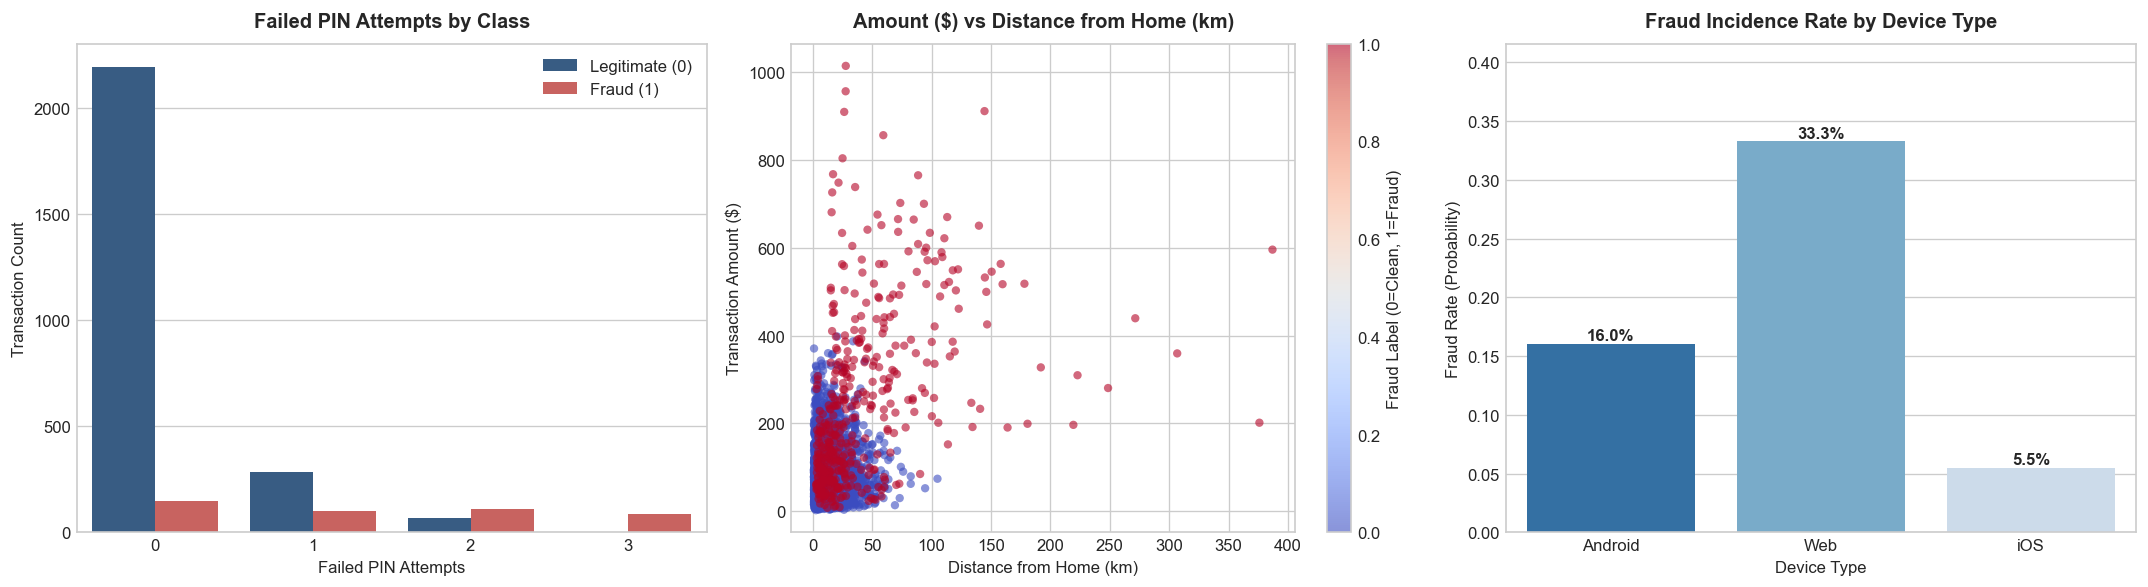

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)

# Plot 1: Failed PIN attempts distribution by fraud status
sns.countplot(data=df_raw, x='failed_pin_attempts', hue='is_fraud', ax=axes[0], palette=['#2b5c8f', '#d9534f'])
axes[0].set_title('Failed PIN Attempts by Class', fontweight='bold', pad=10)
axes[0].set_xlabel('Failed PIN Attempts')
axes[0].set_ylabel('Transaction Count')
axes[0].legend(['Legitimate (0)', 'Fraud (1)'])

# Plot 2: Transaction Amount vs Distance from Home
scatter = axes[1].scatter(
    df_raw['distance_from_home_km'], 
    df_raw['txn_amount'], 
    c=df_raw['is_fraud'], 
    cmap='coolwarm', 
    alpha=0.6, 
    edgecolors='none',
    s=25
)
axes[1].set_title('Amount ($) vs Distance from Home (km)', fontweight='bold', pad=10)
axes[1].set_xlabel('Distance from Home (km)')
axes[1].set_ylabel('Transaction Amount ($)')
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label('Fraud Label (0=Clean, 1=Fraud)')

# Plot 3: Device Type Fraud Rate
device_fraud = df_raw.groupby('device_type')['is_fraud'].mean().reset_index()
sns.barplot(data=device_fraud, x='device_type', y='is_fraud', ax=axes[2], palette='Blues_r')
axes[2].set_title('Fraud Incidence Rate by Device Type', fontweight='bold', pad=10)
axes[2].set_xlabel('Device Type')
axes[2].set_ylabel('Fraud Rate (Probability)')
axes[2].set_ylim(0, max(device_fraud['is_fraud']) * 1.25)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


---
## Section 4: Leak-Free Preprocessing Pipeline & Stratification

To prevent data leakage:
1. Primary IDs (`txn_id`, `customer_id`, `merchant_id`) are stripped from the predictor matrix.
2. A stratified split (75% training, 25% test vault) preserves the exact class ratio across partitions.
3. Preprocessing is encapsulated in a `ColumnTransformer`:
   - Numerical signals (`customer_tenure_months`, `txn_amount`, `distance_from_home_km`, `hour_of_day`, `is_international`, `failed_pin_attempts`) are passed through.
   - Categorical channel signals (`device_type`) are encoded via `OneHotEncoder(drop='first', sparse_output=False)` to prevent dummy variable collinearity.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Feature matrix and target separation
num_features = ['customer_tenure_months', 'txn_amount', 'distance_from_home_km', 'hour_of_day', 'is_international', 'failed_pin_attempts']
cat_features = ['device_type']

X = df_raw[num_features + cat_features]
y = df_raw['is_fraud']

# Leak-free ColumnTransformer pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('nums', 'passthrough', num_features),
        ('cats', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ]
)

# Stratified partition to lock test vault
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Fit strictly on training set; transform test set
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Reconstruct feature names
cat_encoder = preprocessor.named_transformers_['cats']
cat_encoded_names = cat_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names

X_train_df = pd.DataFrame(X_train_proc, columns=all_feature_names)
X_test_df = pd.DataFrame(X_test_proc, columns=all_feature_names)

print(f"Training Matrix Shape: {X_train_df.shape}")
print(f"Test Matrix Shape:     {X_test_df.shape}")
print(f"Encoded Feature Vector: {all_feature_names}")


Training Matrix Shape: (2250, 8)
Test Matrix Shape:     (750, 8)
Encoded Feature Vector: ['customer_tenure_months', 'txn_amount', 'distance_from_home_km', 'hour_of_day', 'is_international', 'failed_pin_attempts', 'device_type_Web', 'device_type_iOS']


---
## Section 5: Cost-Sensitive Gradient Boosted Classification (`XGBClassifier`)

Gradient Boosted Decision Trees (GBDT) are the industry standard for tabular fraud scoring due to their ability to model non-linear interactions, handle mixed feature scales without mandatory normalization, and support sub-millisecond inference latency.

We train an `XGBClassifier` with:
- `n_estimators=100`: Ensemble depth balance.
- `max_depth=4`: Constraining tree complexity to prevent overfitting to rare fraud instances.
- `learning_rate=0.08`: Shrinkage parameter for gradient descent steps.
- `eval_metric='logloss'`: Binary cross-entropy optimization.


In [5]:
from xgboost import XGBClassifier

# Initialize and train XGBoost classifier
model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.08,
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train_df, y_train)

# Inference on unseen test vault
y_prob = model.predict_proba(X_test_df)[:, 1]
print("XGBoost training complete. Inferred probabilities on test vault successfully.")


XGBoost training complete. Inferred probabilities on test vault successfully.


---
## Section 6: Rigorous Model Evaluation & Threshold Tuning

Under class imbalance, ROC-AUC can present an overly optimistic assessment because a large number of True Negatives depresses the False Positive Rate denominator. 

The **Precision-Recall Curve (PR-AUC)** focuses strictly on the minority class (fraud):
- **Precision:** $\frac{TP}{TP + FP}$ (Reliability of fraud alerts).
- **Recall:** $\frac{TP}{TP + FN}$ (Coverage of intercepted fraud).

We benchmark the model using both ROC-AUC and PR-AUC, and compare the default 0.50 cutoff against an operationally calibrated 0.30 risk threshold.


Test Set ROC-AUC Score:      0.9293
Test Set PR-AUC (Avg Prec):  0.7928


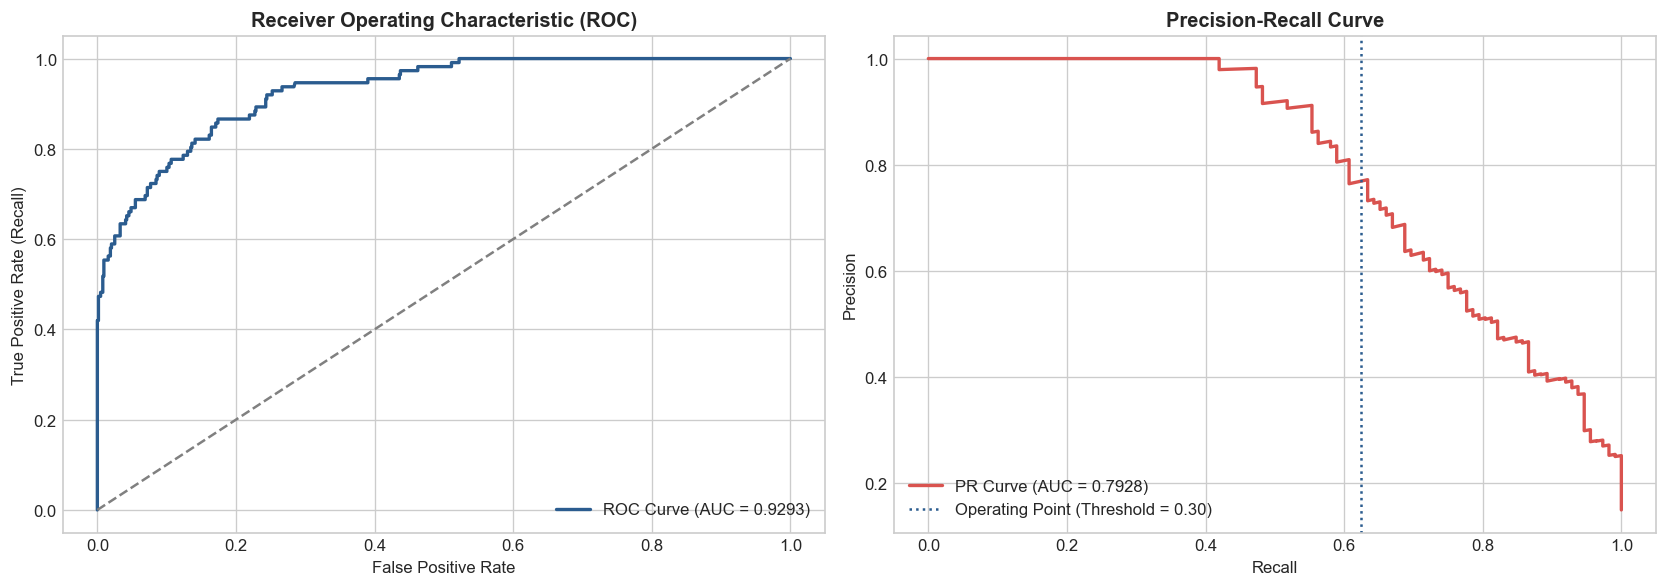


==================== EVALUATION AT THRESHOLD 0.50 ====================
True Negatives: 631 | False Positives: 7
False Negatives: 50 | True Positives:  62
Fraud Recall Rate: 55.4%
Fraud Precision:   89.9%

Classification Report:
              precision    recall  f1-score   support

           0     0.9266    0.9890    0.9568       638
           1     0.8986    0.5536    0.6851       112

    accuracy                         0.9240       750
   macro avg     0.9126    0.7713    0.8209       750
weighted avg     0.9224    0.9240    0.9162       750


==================== EVALUATION AT THRESHOLD 0.30 ====================
True Negatives: 617 | False Positives: 21
False Negatives: 42 | True Positives:  70
Fraud Recall Rate: 62.5%
Fraud Precision:   76.9%

Classification Report:
              precision    recall  f1-score   support

           0     0.9363    0.9671    0.9514       638
           1     0.7692    0.6250    0.6897       112

    accuracy                         0.9160       

In [6]:
from sklearn.metrics import (
    roc_auc_score, roc_curve, 
    precision_recall_curve, auc, 
    confusion_matrix, classification_report
)

# Compute ROC-AUC and PR-AUC
roc_score = roc_auc_score(y_test, y_prob)
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_prob)
pr_auc_score = auc(recalls, precisions)

print(f"Test Set ROC-AUC Score:      {roc_score:.4f}")
print(f"Test Set PR-AUC (Avg Prec):  {pr_auc_score:.4f}")

# Threshold Comparison: 0.50 vs 0.30
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Subplot 1: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'ROC Curve (AUC = {roc_score:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# Subplot 2: Precision-Recall Curve
axes[1].plot(recalls, precisions, color='#d9534f', lw=2, label=f'PR Curve (AUC = {pr_auc_score:.4f})')
axes[1].axvline(x=0.625, color='#2b5c8f', linestyle=':', label='Operating Point (Threshold = 0.30)')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

# Quantitative Scorecard
for thresh in [0.50, 0.30]:
    y_pred_t = (y_prob >= thresh).astype(int)
    cm = confusion_matrix(y_test, y_pred_t)
    print(f"\n==================== EVALUATION AT THRESHOLD {thresh:.2f} ====================")
    print(f"True Negatives: {cm[0, 0]} | False Positives: {cm[0, 1]}")
    print(f"False Negatives: {cm[1, 0]} | True Positives:  {cm[1, 1]}")
    print(f"Fraud Recall Rate: {cm[1, 1] / (cm[1, 0] + cm[1, 1]):.1%}")
    print(f"Fraud Precision:   {cm[1, 1] / (cm[0, 1] + cm[1, 1]):.1%}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_t, digits=4))


---
## Section 7: Explainable AI with SHAP (Cooperative Game Theory)

In fintech operations, black-box predictions are unacceptable:
- **Dispute Resolution:** Chargeback investigators must know why a merchant's settlement was paused or why an account was frozen.
- **Regulatory Compliance (CBN, NDPR, GDPR):** Financial institutions are legally obligated to provide explainable decisions for adverse actions.

We employ **SHAP (SHapley Additive exPlanations)** based on cooperative game theory:
$$\phi_i(x) = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!(|F| - |S| - 1)!}{|F|!} [f_x(S \cup \{i\}) - f_x(S)]$$

Using `shap.TreeExplainer`, we compute exact polynomial-time Shapley values to examine:
1. **Global Feature Attribution:** Mean absolute SHAP importance.
2. **Directional Dynamics:** Beeswarm plot demonstrating how high vs low feature values push risk up or down.
3. **Non-Linear Interactions:** Dependence plot between transaction amount and geographic distance.
4. **Local Forensics:** Waterfall plots explaining individual high-risk and clean transactions.


SHAP Values Matrix Shape: (750, 8)
Model Base Value (Prior Log-Odds): -1.8459


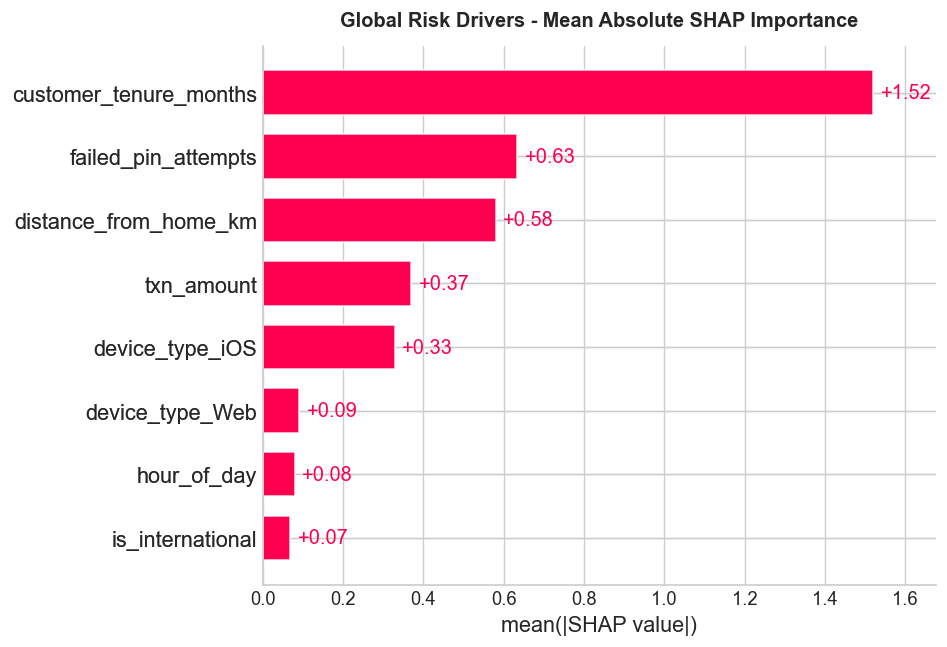

In [7]:
import shap

# Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_df)

print(f"SHAP Values Matrix Shape: {shap_values.values.shape}")
print(f"Model Base Value (Prior Log-Odds): {shap_values.base_values[0]:.4f}")

# Plot 1: Global SHAP Feature Importance
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title('Global Risk Drivers - Mean Absolute SHAP Importance', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


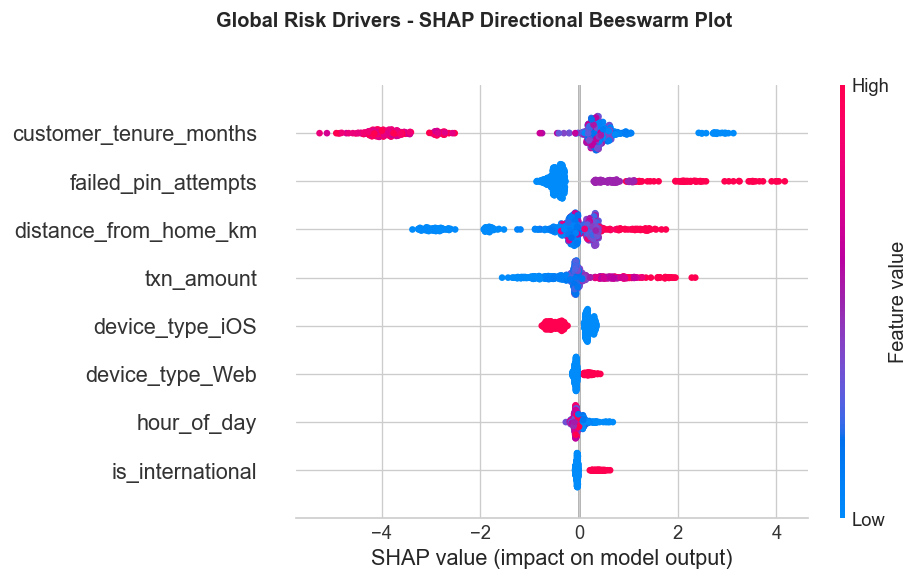

In [8]:
# Plot 2: SHAP Directional Beeswarm Plot
fig = plt.figure(figsize=(9, 5.5), dpi=120)
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.suptitle('Global Risk Drivers - SHAP Directional Beeswarm Plot', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


<Figure size 1080x600 with 0 Axes>

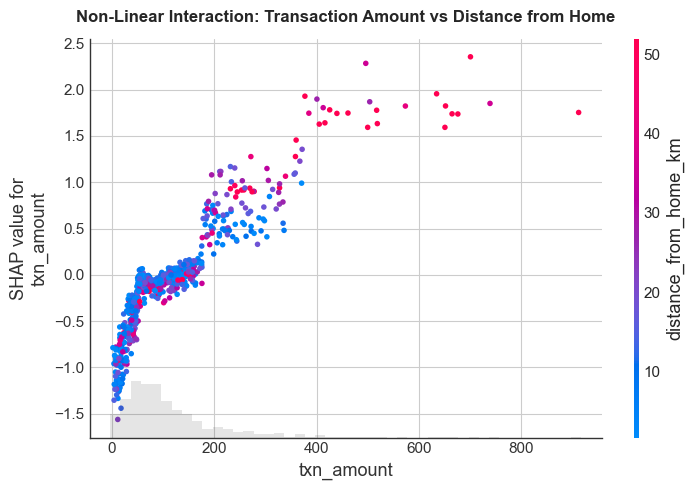

In [9]:
# Plot 3: SHAP Dependence / Interaction Plot
fig = plt.figure(figsize=(9, 5), dpi=120)
shap.plots.scatter(
    shap_values[:, 'txn_amount'], 
    color=shap_values[:, 'distance_from_home_km'], 
    show=False
)
plt.title('Non-Linear Interaction: Transaction Amount vs Distance from Home', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


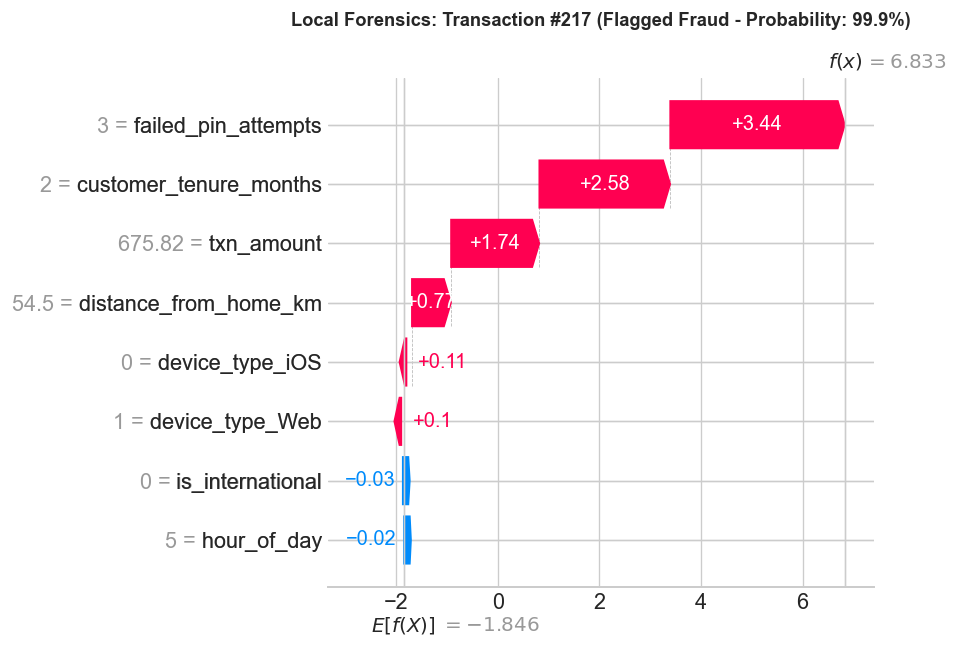

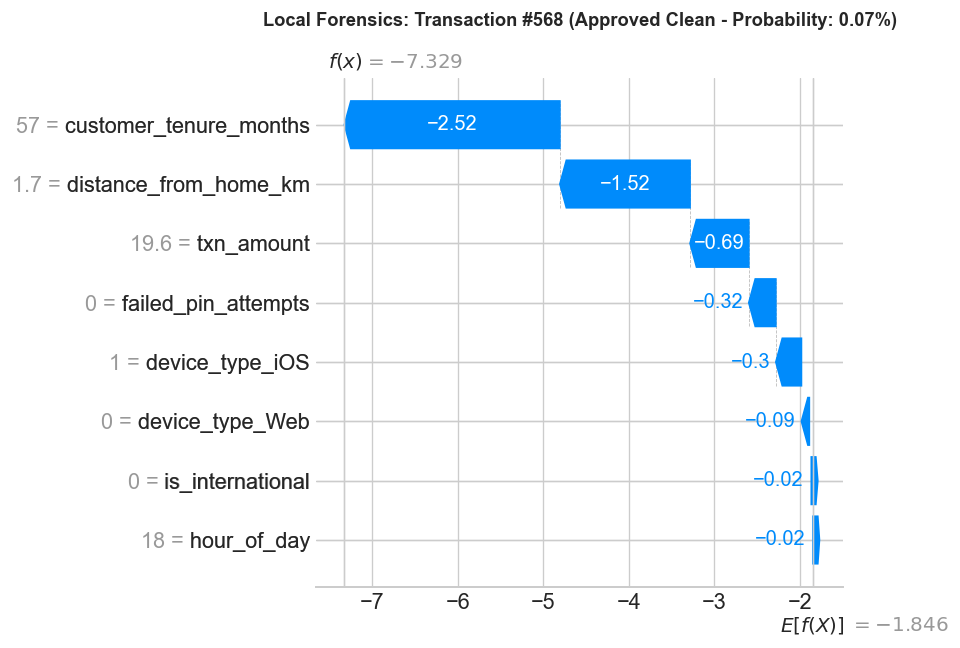

In [10]:
# Plot 4: Local Forensics (Waterfall Plots for Highest Risk vs Lowest Risk Transactions)
high_risk_idx = int(np.argmax(y_prob))
low_risk_idx = int(np.argmin(y_prob))

# High-Risk Transaction Waterfall
fig1, ax1 = plt.subplots(figsize=(9, 5), dpi=120)
shap.plots.waterfall(shap_values[high_risk_idx], show=False)
plt.title(
    f"Local Forensics: Transaction #{high_risk_idx} (Flagged Fraud - Probability: {y_prob[high_risk_idx]*100:.1f}%)",
    fontsize=11, fontweight='bold', pad=15
)
plt.tight_layout()
plt.show()

# Low-Risk Transaction Waterfall
fig2, ax2 = plt.subplots(figsize=(9, 5), dpi=120)
shap.plots.waterfall(shap_values[low_risk_idx], show=False)
plt.title(
    f"Local Forensics: Transaction #{low_risk_idx} (Approved Clean - Probability: {y_prob[low_risk_idx]*100:.2f}%)",
    fontsize=11, fontweight='bold', pad=15
)
plt.tight_layout()
plt.show()


---
## Section 8: Model Serialization & Parity Verification

To deploy the pipeline into a production service:
1. We package the fitted `preprocessor`, trained `model`, list of `encoded_features`, and operating `threshold` (0.30) into an atomic Python dictionary.
2. We serialize the artifact to disk using `joblib.dump()`.
3. We reload the artifact and verify strict 6-decimal numerical parity (`np.allclose`) against the in-memory model.


In [11]:
import joblib
import os

# Assemble production bundle dictionary
bundle_payload = {
    'preprocessor': preprocessor,
    'model': model,
    'encoded_features': all_feature_names,
    'threshold': 0.30
}

# Serialize to disk
pipeline_filename = 'fraud_detection_pipeline.joblib'
joblib.dump(bundle_payload, pipeline_filename)

print(f"Artifact serialized successfully to: {pipeline_filename}")
print(f"Bundle File Size: {os.path.getsize(pipeline_filename) / 1024:.2f} KB")

# Verification: Deserialize and run parity audit
loaded_bundle = joblib.load(pipeline_filename)
sample_5 = X_test.iloc[:5]
sample_5_proc = loaded_bundle['preprocessor'].transform(sample_5)
sample_5_df = pd.DataFrame(sample_5_proc, columns=loaded_bundle['encoded_features'])

pred_original = model.predict_proba(sample_5_df)[:, 1]
pred_loaded = loaded_bundle['model'].predict_proba(sample_5_df)[:, 1]

parity_check = np.allclose(pred_original, pred_loaded, atol=1e-6)
print(f"Numerical Parity Verified (np.allclose atol=1e-6): {parity_check}")
assert parity_check, 'Parity check failed!'


Artifact serialized successfully to: fraud_detection_pipeline.joblib
Bundle File Size: 122.88 KB
Numerical Parity Verified (np.allclose atol=1e-6): True


---
## Section 9: Headless Production Inference Engine & Streamlit Architecture

We construct a headless Python scoring function `predict_transaction()` that accepts raw JSON transaction telemetry, executes the preprocessing transformation, computes fraud probability, and evaluates the decision against the calibrated operating threshold.

This logic powers the production Streamlit web application (`fraud_app.py`) for live monitoring and real-time SHAP risk explainability.


In [12]:
# Headless Production Inference Function
def predict_transaction(transaction_dict: dict, bundle: dict) -> dict:
    df_single = pd.DataFrame([transaction_dict])
    proc_array = bundle['preprocessor'].transform(df_single)
    df_proc = pd.DataFrame(proc_array, columns=bundle['encoded_features'])
    
    prob = float(bundle['model'].predict_proba(df_proc)[:, 1][0])
    threshold = bundle.get('threshold', 0.30)
    decision = 'FLAGGED_HIGH_RISK' if prob >= threshold else 'APPROVED_CLEAN'
    
    return {
        'fraud_probability': round(prob, 4),
        'fraud_percentage': f"{prob * 100:.2f}%",
        'operating_threshold': threshold,
        'decision': decision
    }

# Test Case 1: High-Risk POS Terminal Payload (Off-hours, high failed PINs, large distance)
suspicious_payload = {
    'customer_tenure_months': 3,
    'txn_amount': 2450.0,
    'distance_from_home_km': 620.0,
    'hour_of_day': 3,
    'is_international': 1,
    'failed_pin_attempts': 3,
    'device_type': 'Android'
}

# Test Case 2: Clean Daytime POS Transaction (Domestic, 0 failed PINs, regular customer)
legitimate_payload = {
    'customer_tenure_months': 36,
    'txn_amount': 45.0,
    'distance_from_home_km': 2.5,
    'hour_of_day': 13,
    'is_international': 0,
    'failed_pin_attempts': 0,
    'device_type': 'iOS'
}

res1 = predict_transaction(suspicious_payload, loaded_bundle)
res2 = predict_transaction(legitimate_payload, loaded_bundle)

print("--- Telemetry Test 1 (Suspicious Payload) ---")
for k, v in res1.items():
    print(f"  {k}: {v}")

print("\n--- Telemetry Test 2 (Legitimate Payload) ---")
for k, v in res2.items():
    print(f"  {k}: {v}")


--- Telemetry Test 1 (Suspicious Payload) ---
  fraud_probability: 0.9992
  fraud_percentage: 99.92%
  operating_threshold: 0.3
  decision: FLAGGED_HIGH_RISK

--- Telemetry Test 2 (Legitimate Payload) ---
  fraud_probability: 0.003
  fraud_percentage: 0.30%
  operating_threshold: 0.3
  decision: APPROVED_CLEAN
